In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

In [22]:
MAX_ITERACOES = 40
INERCIA = 0.2
COGNITIVO = 0.5
SOCIAL = 0.5
QTD_PARTICULAS = 40

N_DIMENSOES = 5
LIMITE = 5.12
PENALIDADE = 1000

In [23]:
def calcula_rastrigin(posicao):
    """Função de Rastrigin apresentada na Equação 1 do PDF."""
    n = len(posicao)
    return 10 * n + np.sum(posicao**2 - 10 * np.cos(2 * np.pi * posicao))


def calcula_penalidade(posicao):
    """Penaliza violações das restrições g(x) <= 0 e h(x) = 0."""
    g = np.sin(2 * np.pi * posicao) + 0.5
    h = np.cos(2 * np.pi * posicao) + 0.5

    violacao_g = np.maximum(g, 0)
    return PENALIDADE * (np.sum(violacao_g**2) + np.sum(h**2))


def calcula_fitness(posicao):
    
    posicao = np.asarray(posicao, dtype=float)

    # Soluções fora do espaço de busca são inválidas.
    if np.any(posicao < -LIMITE) or np.any(posicao > LIMITE):
        return float("inf")

    ponto_otimo = np.full(len(posicao), -1 / 3)
    distancia = np.linalg.norm(posicao - ponto_otimo)

    return distancia + calcula_penalidade(posicao)

In [24]:
def inicializa_particulas(quantidade):
    registros = []

    for _ in range(quantidade):
        # Cada dimensão é sorteada uniformemente em [-5.12, 5.12].
        posicao = np.random.uniform(-LIMITE, LIMITE, size=N_DIMENSOES)

        # Velocidade inicial aleatória para cada dimensão.
        velocidade = np.random.uniform(-1, 1, size=N_DIMENSOES)

        fitness = calcula_fitness(posicao)

        registros.append({
            "posicao": posicao.copy(),
            "velocidade": velocidade.copy(),
            "fitness": fitness,
            "pbest_posicao": posicao.copy(),
            "pbest": fitness
        })

    return pd.DataFrame(registros)

In [25]:
def calcula_velocidade(inercia, cognitivo, social,
                       velocidade, posicao, pbest_posicao, gbest_posicao):
    r1 = np.random.random(size=N_DIMENSOES)
    r2 = np.random.random(size=N_DIMENSOES)

    return (
        inercia * velocidade
        + cognitivo * r1 * (pbest_posicao - posicao)
        + social * r2 * (gbest_posicao - posicao)
    )

In [26]:
def executa_pso():
    particulas = inicializa_particulas(QTD_PARTICULAS)

    # Melhor posição global inicial, baseada no melhor pbest da população.
    melhor_indice = particulas["pbest"].idxmin()
    gbest_posicao = particulas.at[melhor_indice, "pbest_posicao"].copy()
    gbest = particulas.at[melhor_indice, "pbest"]

    historico_melhor = []
    historico_media = []
    historico_desvio = []
    historico_posicoes = [(0, np.stack(particulas["posicao"].to_numpy()).copy())]

    for iteracao in range(MAX_ITERACOES):
        # Atualiza todas as partículas usando o gbest da geração anterior.
        for indice, linha in particulas.iterrows():
            posicao = linha["posicao"].copy()
            velocidade = linha["velocidade"].copy()
            pbest_posicao = linha["pbest_posicao"].copy()

            nova_velocidade = calcula_velocidade(
                INERCIA, COGNITIVO, SOCIAL,
                velocidade, posicao, pbest_posicao, gbest_posicao
            )

            nova_posicao = posicao + nova_velocidade

            # Mantém todas as dimensões dentro do espaço de busca.
            nova_posicao = np.clip(nova_posicao, -LIMITE, LIMITE)

            fitness = calcula_fitness(nova_posicao)

            particulas.at[indice, "velocidade"] = nova_velocidade
            particulas.at[indice, "posicao"] = nova_posicao
            particulas.at[indice, "fitness"] = fitness

            # Atualiza o melhor individual.
            if fitness < particulas.at[indice, "pbest"]:
                particulas.at[indice, "pbest"] = fitness
                particulas.at[indice, "pbest_posicao"] = nova_posicao.copy()

        # Atualiza o melhor global somente depois de atualizar a população.
        melhor_indice = particulas["pbest"].idxmin()
        melhor_fitness_geracao = particulas.at[melhor_indice, "pbest"]

        if melhor_fitness_geracao < gbest:
            gbest = melhor_fitness_geracao
            gbest_posicao = particulas.at[melhor_indice, "pbest_posicao"].copy()

        fitness_populacao = particulas["fitness"].to_numpy(dtype=float)
        historico_melhor.append(gbest)
        historico_media.append(np.mean(fitness_populacao))
        historico_desvio.append(np.std(fitness_populacao))

        if (iteracao + 1) % 10 == 0:
            posicoes = np.stack(particulas["posicao"].to_numpy()).copy()
            historico_posicoes.append((iteracao + 1, posicoes))

    return {
        "melhor_posicao": gbest_posicao.copy(),
        "melhor_fitness": float(gbest),
        "melhor_rastrigin": float(calcula_rastrigin(gbest_posicao)),
        "historico_melhor": historico_melhor,
        "historico_media": historico_media,
        "historico_desvio": historico_desvio,
        "historico_posicoes": historico_posicoes,
        "particulas": particulas
    }

In [27]:
resultado = executa_pso()

print("Melhor indivíduo encontrado:")
print(resultado["melhor_posicao"])
print("Fitness (distância com penalidade):", resultado["melhor_fitness"])
print("Valor da função de Rastrigin:", resultado["melhor_rastrigin"])

Melhor indivíduo encontrado:
[ 2.66158113 -3.35731168 -0.37153952  1.66356678 -1.30239155]
Fitness (distância com penalidade): 89.21833079202469
Valor da função de Rastrigin: 99.79069665679128


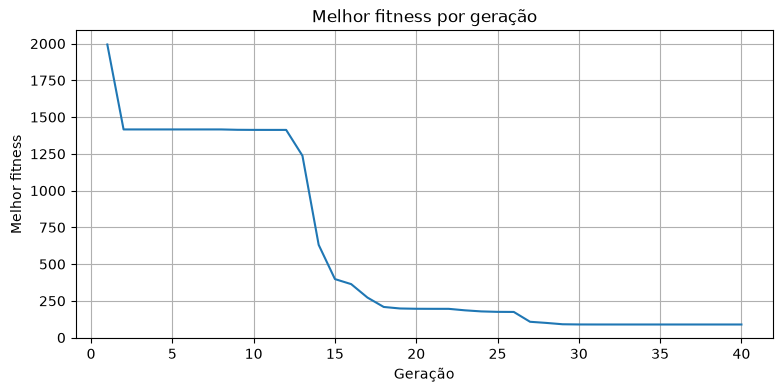

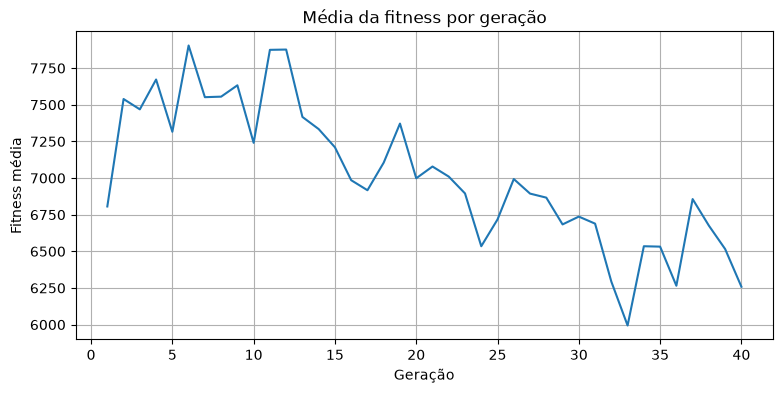

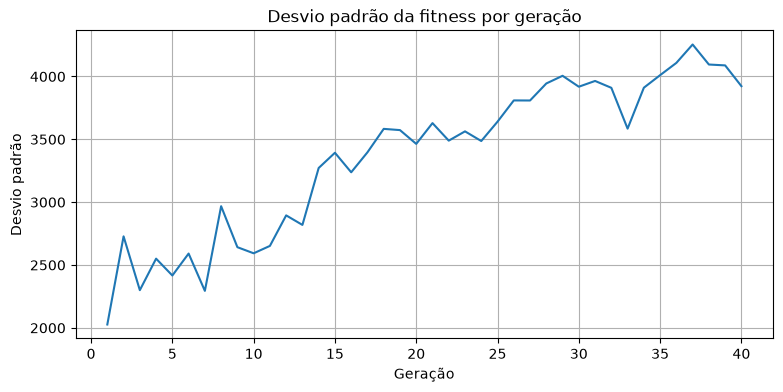

In [28]:
geracoes = np.arange(1, MAX_ITERACOES + 1)

plt.figure(figsize=(9, 4))
plt.plot(geracoes, resultado["historico_melhor"])
plt.xlabel("Geração")
plt.ylabel("Melhor fitness")
plt.title("Melhor fitness por geração")
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(geracoes, resultado["historico_media"])
plt.xlabel("Geração")
plt.ylabel("Fitness média")
plt.title("Média da fitness por geração")
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(geracoes, resultado["historico_desvio"])
plt.xlabel("Geração")
plt.ylabel("Desvio padrão")
plt.title("Desvio padrão da fitness por geração")
plt.grid(True)
plt.show()

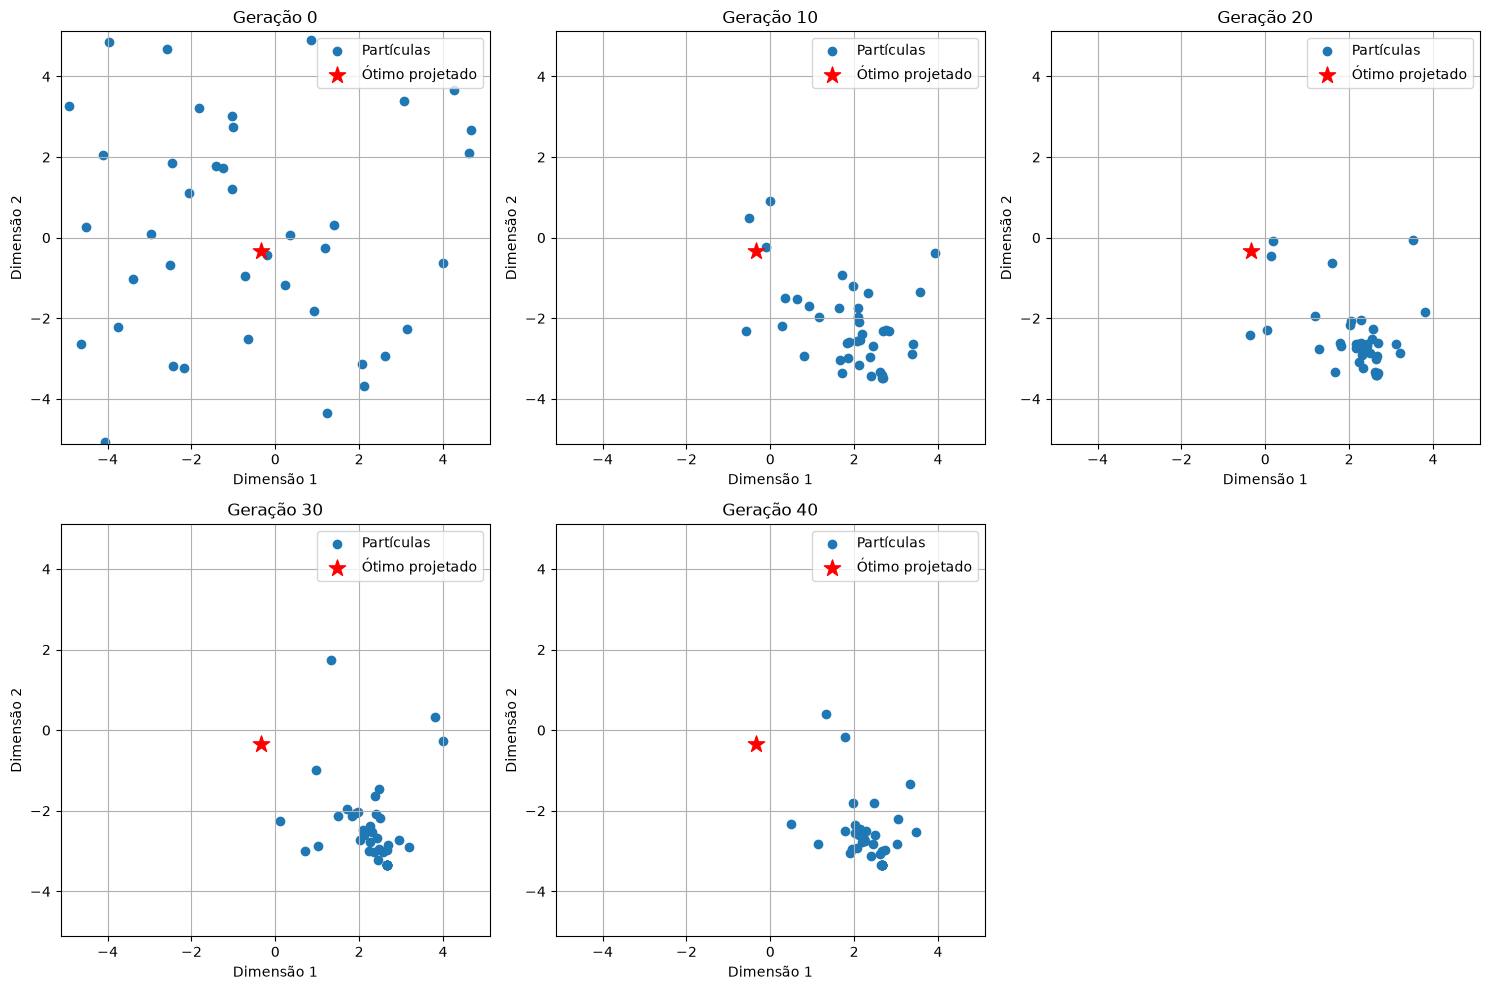

In [29]:
historico = resultado["historico_posicoes"]
colunas = 3
linhas = int(np.ceil(len(historico) / colunas))

fig, axes = plt.subplots(linhas, colunas, figsize=(15, 5 * linhas), squeeze=False)
axes = axes.flatten()

for i, (numero_iteracao, posicoes) in enumerate(historico):
    axes[i].scatter(posicoes[:, 0], posicoes[:, 1], label="Partículas")
    axes[i].scatter(-1/3, -1/3, color="red", marker="*", s=150,
                    label="Ótimo projetado")
    axes[i].set_title(f"Geração {numero_iteracao}")
    axes[i].set_xlim(-LIMITE, LIMITE)
    axes[i].set_ylim(-LIMITE, LIMITE)
    axes[i].set_xlabel("Dimensão 1")
    axes[i].set_ylabel("Dimensão 2")
    axes[i].grid(True)
    axes[i].legend()

for i in range(len(historico), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [30]:
resultados_20 = [executa_pso() for _ in range(20)]

melhores_fitness = np.array([
    resultado["melhor_fitness"] for resultado in resultados_20
])

melhor_execucao = int(np.argmin(melhores_fitness))
melhor_resultado = resultados_20[melhor_execucao]

print("Melhor indivíduo entre as 20 execuções:")
print(melhor_resultado["melhor_posicao"])
print("Fitness desse indivíduo:", melhor_resultado["melhor_fitness"])
print("Média das melhores fitness:", np.mean(melhores_fitness))
print("Desvio padrão das melhores fitness:", np.std(melhores_fitness))

Melhor indivíduo entre as 20 execuções:
[-0.33208276 -2.35668277  0.67753244  3.63603117  0.65293326]
Fitness desse indivíduo: 52.81483678885437
Média das melhores fitness: 420.323468688937
Desvio padrão das melhores fitness: 342.71695361068095
